# TIA — frozen encoders into the shared feature cache

This notebook turns every clip of the frozen protocol into the two arrays that
`train_tia.ipynb` trains on, and writes them into the shared Drive cache:

```
<DATA>/cached_features/dinov2-small/<clip_id>.npy       float16  (16, 384)
<DATA>/cached_features/wavlm-base-plus/<clip_id>.npy    float16  (64, 768)
```

Run it **once**, before training; again only to add an encoder or to rebuild a cache whose
settings changed. The training notebook never decodes a video.

| | |
|---|---|
| **Time** | ~40–60 min on a T4 for the full protocol and both encoders |
| **Writes** | `cached_features/<encoder>/` on the shared folder + one `manifest.json` per encoder |
| **Resumable** | yes — a clip whose `.npy` exists is skipped, so a disconnect costs one clip |
| **Reads** | `clips/`, `audio/`, `dataset.csv`, `splits/` from the shared folder |

Why a cache:

* the backbones are **frozen** (`docs/architectures.md`, Paradigm 1), so this pass is the only
  heavy compute: training the fusion network afterwards takes under a minute per epoch;
* the folder is named after the **encoder**, never the direction (`docs/data.md`), so another
  direction that uses DINOv2 or WavLM finds these files already there;
* the preprocessing *is* the cache. `manifest.json` records frames, image size, face crop,
  audio tokens, the model revision and the `dataset.csv` fingerprint, and a folder built with
  other settings is refused instead of being silently mixed.

The test clips are encoded too — the split files decide only *which* clips, never how they
are encoded — so the final evaluation does not need a second extraction pass.

## 0 — Setup

Colab only, and Drive first: every artefact is written straight there.

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
# `lib/` and the frozen protocol are versioned in git; Drive holds only the data.
import os
if not os.path.isdir("/content/DeepLearningCourse/.git"):
    !git clone -q https://github.com/mattsays/DeepLearningCourse /content/DeepLearningCourse
%cd /content/DeepLearningCourse/lie-detector
!git pull -q
import sys; sys.path.insert(0, '.')

/content/DeepLearningCourse/lie-detector


In [30]:
# Pinned on purpose (docs/colab.md), with one escape hatch: Python 3.13 has no wheel for the
# tokenizers that transformers 4.46 pins, so on a newer Colab image we take the newest 4.x.
# Either way the exact versions and model revisions land in manifest.json, so a cache built
# today stays identifiable after the Colab image changes.
import subprocess
import sys

package = "transformers==4.46.3" if sys.version_info < (3, 13) else "transformers>=4.46,<5"
subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# --no-deps: facenet-pytorch needs torch/torchvision, which Colab already has; letting pip
# resolve them is how a Colab image gets broken.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                "facenet-pytorch==2.6.0"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "soundfile"], check=True)
print("installed")

installed


In [31]:
import json
import os
import time
from datetime import datetime, timezone
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm import tqdm   # the console bar: it renders in Colab even when the widget does not
import transformers
from transformers import (AutoFeatureExtractor, AutoImageProcessor, AutoModel, AutoTokenizer,
                          Dinov2Model, WavLMModel, WhisperForConditionalGeneration,
                          WhisperProcessor)
from facenet_pytorch import MTCNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device", device)

torch 2.14.1+cu130 | transformers 4.57.6 | device cuda


## 1 — Settings

One entry per **encoding model**. The key is the folder under `cached_features/` and it is the
model name, not the direction.

The DINOv2 frame count and the WavLM token count are the two numbers the fusion model will
see; changing either produces a different cache, which the manifest refuses to mix.

In [32]:
from lib.dataset import Protocol, Clips, cache_dir, stage_media

DATA = Path("/content/drive/MyDrive/dolos")
SEED = 0

ENCODERS = {
    #"dinov2-small":    {"kind": "video", "hf_id": "facebook/dinov2-small"},
    #"wavlm-base-plus": {"kind": "audio", "hf_id": "microsoft/wavlm-base-plus"},
    # Whisper transcribes, a frozen sentence encoder embeds the transcript: one 384-vector per
    # clip. `transcripts.json` is written next to the arrays so the words can be read.
    # English-only and distilled from whisper-small: about six times faster, a small WER cost
    # on noisy speech. Swap "asr" back to "openai/whisper-small" if the transcripts look wrong.
    "text-minilm":     {"kind": "text", "hf_id": "sentence-transformers/all-MiniLM-L6-v2",
                        "asr": "distil-whisper/distil-small.en"},
    # Upper body instead of the face: same backbone, same frames, wider box. Uncomment to
    # build a second video cache, then point VIDEO_ENCODER at it in train.ipynb. At 16 frames
    # (≈3 fps) the face moves faster than the sampling, the body does not — this is the
    # variant that can show whether the visual channel is useless or just under-sampled.
    #"dinov2-small-body": {"kind": "video", "hf_id": "facebook/dinov2-small",
    #                      "face_margin": 1.75},
}

FRAMES = 16            # frames per clip, evenly spaced (docs/architectures.md, Paradigm 1)
IMAGE_SIZE = 224       # DINOv2 input resolution
FACE_CROP = True       # MTCNN crop; falls back to the centre of the frame when no face is found
FACE_MARGIN = 0.25     # extra border around the detected box, as a fraction of its side
AUDIO_TOKENS = 64      # WavLM tokens after temporal pooling (PECL uses L = 64)
FORCE = False          # True = rebuild a cache whose settings no longer match

torch.manual_seed(SEED)
np.random.seed(SEED)
encoders = {}

assert DATA.is_dir(), f"{DATA} not found: mount Drive and add the 'dolos' shortcut"
print({name: cache_dir(name, DATA) for name in ENCODERS})

{'text-minilm': PosixPath('/content/drive/MyDrive/dolos/cached_features/text-minilm')}


## 2 — Which clips

The protocol is one frozen set of splits. The union of the five folds **plus the test set** is
encoded, because the cache is keyed by clip, not by fold: one extraction pass serves every run.
Labels are used only for the summary counts and for the sanity probe at the end; never to
choose or encode a clip.

Clips that are in no split are not encoded; clips that lost their media on Drive cannot be
encoded and are reported rather than silently skipped.

Clips **without audio** stay in the frozen splits but not in this cache: the fusion model needs
both channels. That is a dataset gap, not a cache gap — either the wav can be re-extracted from
the clip, or the clip is lost for every audio-visual direction. Section 9 shows the intersection
(`cached_ids`) the training notebook must apply.

In [33]:
folds = Protocol.load(DATA / "splits")      # verifies the manifest hashes

# The mp4/wav are read once per clip: copy them off the mount first (docs/data.md).
MEDIA = stage_media(DATA)                    # /content/dolos-local: clips/ + audio/, ~780 MB
clips = Clips.load(MEDIA)
print(clips.describe_source())

split_ids = []
for fold in range(1, folds.folds + 1):
    for part in folds.subject(fold):
        split_ids += part
split_ids += folds.test()
split_ids = list(dict.fromkeys(split_ids))  # union, stable order

missing = clips.missing_from(split_ids)
assert not missing, f"{len(missing)} split clips are not in dataset.csv (first {missing[:3]})"

ids = clips.with_media(split_ids)
print(f"protocol {len(split_ids)} clips  ->  {len(ids)} with media on disk")

left_out = sorted(set(clips.available()) - set(split_ids))
if left_out:
    print(f"{len(left_out)} available clips are in no split (first {left_out[:3]}): not encoded")

# The fusion model needs both channels: a clip without audio cannot be used by TIA.
no_audio = [clip_id for clip_id in ids if clips[clip_id].audio is None]
if no_audio:
    print(f"{len(no_audio)} clips have no audio on disk and are left out (first {no_audio[:3]})")
    drop = set(no_audio)
    ids = [clip_id for clip_id in ids if clip_id not in drop]

print(clips.describe(ids))

# duration_expected is the annotated range; it is only a fallback for when OpenCV cannot
# read a frame count. The clip itself stays the source of truth for the audio.
table = pd.read_csv(DATA / "dataset.csv", dtype=str).set_index("clip_id")
durations = pd.to_numeric(table["duration_expected"], errors="coerce").fillna(0.0).to_dict()

dataset.csv sha256:8fa198b1fe71  1678 clips  1452 with media
protocol 1452 clips  ->  1452 with media on disk
153 clips have no audio on disk and are left out (first ['an_wilty_ep18_lie6', 'an_wilty_ep18_lie7', 'an_wilty_ep18_lie8'])
{'clips': 1299, 'subjects': 145, 'deception': 52.7, 'pos_weight': 0.896, 'female': 20.2, 'majority_baseline': 52.7}


## 3 — Frames and faces

**Frame sampling.** `FRAMES` frames spread evenly over the clip. They are decoded with a
sequential `grab()` rather than 16 seeks: OpenCV seeking lands on a keyframe, and with a long
GOP it can return the wrong picture or nothing at all — a silent corruption of the cache.

**Face crop.** PECL crops the speaker's face with MTCNN before the visual backbone, and the
DOLOS clips are full game-show frames, so the face is small in the frame. MTCNN runs on a
downscaled copy (fast) and the box is scaled back to the original frame, so the crop keeps the
full resolution. The box is expanded by `FACE_MARGIN` and squared before the resize, so the
aspect ratio is not distorted.

**Fallback.** When no face is found, the crop is the centred square of the whole frame — the
same shape, so a clip with one bad detection degrades instead of disappearing.

In [34]:
DETECT_SIDE = 640      # MTCNN works on a downscaled copy; the crop comes from the original
mtcnn = (MTCNN(keep_all=False, device=device, min_face_size=40, factor=0.709,
               post_process=False) if FACE_CROP else None)


def sample_frames(video_path, duration):
    """FRAMES frames, spread evenly over the clip, in BGR."""
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f"cannot open {video_path}")

    total = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = capture.get(cv2.CAP_PROP_FPS) or 0.0
    if total <= 0 and fps > 0 and duration > 0:
        total = int(round(fps * duration))
    if total <= 0:                       # last resort: count the frames, then decode again
        while capture.grab():
            total += 1
        capture.release()
        capture = cv2.VideoCapture(str(video_path))
        if not capture.isOpened():
            raise RuntimeError(f"cannot re-open {video_path}")
    if total <= 0:
        total = FRAMES

    targets = np.linspace(0, max(total - 1, 1), FRAMES).round().astype(int)
    wanted = set(targets.tolist())
    frames, index = [], 0
    while index <= int(targets.max()):
        if not capture.grab():
            break
        if index in wanted:
            ok, frame = capture.retrieve()
            if ok:
                frames.append(frame)
        index += 1
    capture.release()

    if not frames:
        raise RuntimeError(f"no frame decoded from {video_path}")
    while len(frames) < FRAMES:          # the file is shorter than the annotation says
        frames.append(frames[-1])
    return frames[:FRAMES]


def face_box(frame):
    """Box of the most confident face, in original-frame coordinates, or None."""
    height, width = frame.shape[:2]
    scale = DETECT_SIDE / max(height, width)
    small = frame if scale >= 1 else cv2.resize(
        frame, (int(width * scale), int(height * scale)), interpolation=cv2.INTER_AREA)
    boxes, probs = mtcnn.detect(Image.fromarray(cv2.cvtColor(small, cv2.COLOR_BGR2RGB)))
    if boxes is None:
        return None
    score = float(np.asarray(probs).reshape(-1)[0]) if probs is not None else 0.0
    if score < 0.90:
        return None
    return np.asarray(boxes, dtype=np.float64).reshape(-1)[:4] / scale


def centre_box(frame):
    """The centred square of the whole frame, used when no face is found."""
    height, width = frame.shape[:2]
    side = min(height, width)
    return ((width - side) / 2, (height - side) / 2,
            (width + side) / 2, (height + side) / 2)


def square_crop(frame, box, size=IMAGE_SIZE, margin=FACE_MARGIN):
    height, width = frame.shape[:2]
    x1, y1, x2, y2 = box
    centre_x, centre_y = (x1 + x2) / 2.0, (y1 + y2) / 2.0
    side = min(max(x2 - x1, y2 - y1) * (1.0 + 2.0 * margin), float(min(height, width)))
    side = max(side, 8.0)
    half = side / 2.0
    centre_x = min(max(centre_x, half), width - half)
    centre_y = min(max(centre_y, half), height - half)
    left, top = int(round(centre_x - half)), int(round(centre_y - half))
    crop = frame[max(top, 0):min(top + int(round(side)), height),
                 max(left, 0):min(left + int(round(side)), width)]
    return cv2.resize(crop, (size, size), interpolation=cv2.INTER_AREA)


def model_input(clip_id, kind, margin=FACE_MARGIN):
    """What one encoder consumes: 16 RGB crops, or the path of the 16 kHz wav."""
    clip = clips[clip_id]
    if kind in ("audio", "text"):
        if clip.audio is None:
            raise RuntimeError(f"{clip_id}: no audio on disk")
        return {"audio": str(clip.audio), "clip_id": clip_id}

    frames = sample_frames(clip.video, durations.get(clip_id, 0.0))
    crops = []
    for frame in frames:
        box = face_box(frame)
        crops.append(square_crop(frame, box, margin=margin) if box is not None
                     else square_crop(frame, centre_box(frame), margin=0.0))
    return {"frames": [cv2.cvtColor(crop, cv2.COLOR_BGR2RGB) for crop in crops]}

## 4 — The encoders

Both are frozen and evaluated under `torch.no_grad()`: only the fusion network will be trained.

* `VideoEncoder` — DINOv2, one CLS vector per frame. The processor's resize/centre-crop is
  switched off because the crops are already `IMAGE_SIZE`; letting it run would zoom another
  12% into the face for no reason.
* `AudioEncoder` — WavLM's last hidden state (50 tokens/s), average-pooled over time to
  `AUDIO_TOKENS`, so every clip has the same shape and the training loop needs no padding mask.
  The pooling is deterministic and parameter-free; it is part of the cache settings.

Both return `float16`. DINOv2 and WavLM weights stay in `float32` and inference runs under
autocast, which is what keeps the run inside a T4's memory.

In [35]:
class VideoEncoder:
    """Frozen DINOv2: the CLS token of every frame -> (FRAMES, hidden)."""

    def __init__(self, hf_id):
        self.processor = AutoImageProcessor.from_pretrained(hf_id)
        self.model = Dinov2Model.from_pretrained(hf_id).to(device).eval()
        self.revision = getattr(self.model.config, "_commit_hash", None)
        self.shape = (FRAMES, self.model.config.hidden_size)

    @torch.no_grad()
    def __call__(self, payload):
        images = [Image.fromarray(frame) for frame in payload["frames"]]
        pixels = self.processor(images=images, do_resize=False, do_center_crop=False,
                                return_tensors="pt")["pixel_values"].to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16,
                            enabled=device.type == "cuda"):
            cls = self.model(pixel_values=pixels).last_hidden_state[:, 0]
        return cls.float().cpu().numpy().astype(np.float16)


class AudioEncoder:
    """Frozen WavLM: last hidden state, average-pooled to AUDIO_TOKENS -> (AUDIO_TOKENS, hidden)."""

    def __init__(self, hf_id):
        self.feature_extractor = AutoFeatureExtractor.from_pretrained(hf_id)
        self.model = WavLMModel.from_pretrained(hf_id).to(device).eval()
        self.revision = getattr(self.model.config, "_commit_hash", None)
        self.shape = (AUDIO_TOKENS, self.model.config.hidden_size)

    @torch.no_grad()
    def __call__(self, payload):
        speech, sample_rate = sf.read(payload["audio"], dtype="float32", always_2d=False)
        if speech.ndim > 1:
            speech = speech.mean(axis=1)
        if sample_rate != 16000:
            raise RuntimeError(f"{payload['audio']}: {sample_rate} Hz, expected 16000")

        inputs = self.feature_extractor(speech, sampling_rate=sample_rate, return_tensors="pt")
        # Only the waveform: passing the all-ones attention mask as well makes WavLM hand both
        # a key_padding_mask and an attn_mask to MultiheadAttention, which warns on every clip.
        inputs = {"input_values": inputs["input_values"].to(device)}
        with torch.autocast(device_type=device.type, dtype=torch.float16,
                            enabled=device.type == "cuda"):
            hidden = self.model(**inputs).last_hidden_state[0]
        hidden = hidden.float()                                  # (T, hidden)
        pooled = F.adaptive_avg_pool1d(hidden.T.unsqueeze(0), AUDIO_TOKENS)
        return pooled[0].T.cpu().numpy().astype(np.float16)


class TextEncoder:
    """Frozen Whisper -> frozen sentence encoder: one L2-normalised 384-vector per clip.

    The transcript is kept in ``transcripts`` and written beside the cache, because the first
    question to ask of this stream is whether the words give the answer away.
    """

    def __init__(self, asr_id, hf_id):
        self.asr_processor = WhisperProcessor.from_pretrained(asr_id)
        self.asr = WhisperForConditionalGeneration.from_pretrained(asr_id).to(device).eval()
        self.tokenizer = AutoTokenizer.from_pretrained(hf_id)
        self.model = AutoModel.from_pretrained(hf_id).to(device).eval()
        self.revision = getattr(self.model.config, "_commit_hash", None)
        self.shape = (self.model.config.hidden_size,)
        self.transcripts = {}

    @torch.no_grad()
    def __call__(self, payload):
        speech, sample_rate = sf.read(payload["audio"], dtype="float32", always_2d=False)
        if speech.ndim > 1:
            speech = speech.mean(axis=1)

        features = self.asr_processor(speech, sampling_rate=sample_rate,
                                      return_tensors="pt").input_features.to(device)
        # an English-only checkpoint (distil-whisper) rejects `language`/`task` outright
        options = {"max_new_tokens": 128}
        if getattr(self.asr.generation_config, "is_multilingual", True):
            options.update(language="en", task="transcribe")
        with torch.autocast(device_type=device.type, dtype=torch.float16,
                            enabled=device.type == "cuda"):
            generated = self.asr.generate(features, **options)
        text = self.asr_processor.batch_decode(generated, skip_special_tokens=True)[0].strip()
        self.transcripts[payload["clip_id"]] = text

        tokens = self.tokenizer(text or ".", return_tensors="pt", truncation=True,
                                max_length=128).to(device)
        hidden = self.model(**tokens).last_hidden_state
        mask = tokens["attention_mask"].unsqueeze(-1)
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
        pooled = F.normalize(pooled, dim=-1)
        return pooled[0].float().cpu().numpy().astype(np.float16)


def build_encoder(spec):
    if spec["kind"] == "text":
        return TextEncoder(spec["asr"], spec["hf_id"])
    return {"video": VideoEncoder, "audio": AudioEncoder}[spec["kind"]](spec["hf_id"])

## 5 — The cache folder

```
cached_features/<encoder>/
├── <clip_id>.npy      one array per clip
└── manifest.json      settings, model revision, dataset fingerprint, counts
```

`manifest.json` is what makes a shared, unversioned cache safe:

* a folder whose `settings` differ from the current ones is **refused**, not mixed — the fix is
  `FORCE = True` (which deletes the old arrays first, so an interrupted rebuild cannot leave a
  half-old cache) or a new encoder name;
* the model revision and the `dataset.csv` fingerprint are recorded, so two notebooks reading
  the same folder can tell whether they are looking at the same features;
* a write goes to a temporary file first and is renamed, so a disconnect can never leave a
  half-written `.npy` that the next run would happily skip.

In [36]:
def cache_settings(name, spec):
    """Everything that changes the content of an array. A mismatch means a different cache."""
    return {
        "encoder": name,
        "hf_id": spec["hf_id"],
        "kind": spec["kind"],
        "frames": FRAMES if spec["kind"] == "video" else None,
        "image_size": IMAGE_SIZE if spec["kind"] == "video" else None,
        "face_crop": FACE_CROP if spec["kind"] == "video" else None,
        "face_margin": spec.get("face_margin", FACE_MARGIN) if spec["kind"] == "video" else None,
        "audio_tokens": AUDIO_TOKENS if spec["kind"] == "audio" else None,
        "asr": spec.get("asr"),
        "dtype": "float16",
    }


class FeatureCache:
    """`<clip_id>.npy` files plus the manifest that says how they were built."""

    def __init__(self, directory, settings, force=False):
        self.dir = Path(directory)
        self.dir.mkdir(parents=True, exist_ok=True)
        self.manifest = self.dir / "manifest.json"
        for stale in self.dir.glob(".*.tmp.npy"):
            stale.unlink()

        previous = (json.loads(self.manifest.read_text())
                    if self.manifest.exists() else None)
        if previous is not None and previous.get("settings") == settings:
            self.meta = previous
        elif previous is not None and not force:
            raise RuntimeError(
                f"{self.dir} was built with different settings.\n"
                f"  on disk:   {previous.get('settings')}\n"
                f"  requested: {settings}\n"
                "Set FORCE = True to rebuild it, or use another encoder name."
            )
        else:
            if previous is not None:      # FORCE with other settings: never a half-old cache
                for old in self.dir.glob("*.npy"):
                    old.unlink()
            self.meta = {
                "encoder": settings["encoder"],
                "settings": settings,
                "hf_revision": None,
                "dataset_fingerprint": None,
                "versions": {"torch": torch.__version__,
                             "transformers": transformers.__version__,
                             "opencv": cv2.__version__,
                             "numpy": np.__version__},
                "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                "status": "running",
                "clips": 0,
                "failed": {},
                "seconds": None,
            }
        self.meta["status"] = "running"
        self.save()

    def save(self):
        temporary = self.dir / ".manifest.json.tmp"
        temporary.write_text(json.dumps(self.meta, indent=2))
        os.replace(temporary, self.manifest)

    def path(self, clip_id):
        return self.dir / f"{clip_id}.npy"

    def pending(self, clip_ids, force=False):
        return [clip_id for clip_id in clip_ids if force or not self.path(clip_id).exists()]

    def write(self, clip_id, array):
        temporary = self.dir / f".{clip_id}.tmp.npy"
        np.save(temporary, np.asarray(array, dtype=np.float16))
        os.replace(temporary, self.path(clip_id))

    def finalize(self, expected, failures, seconds):
        self.meta.update(
            status="complete",
            clips=len(list(self.dir.glob("*.npy"))),
            expected=expected,
            failed=failures,
            seconds=round(seconds, 1),
            finished=datetime.now(timezone.utc).isoformat(timespec="seconds"),
        )
        self.save()

## 6 — The encoding loop

One pass per encoder: skip what is already cached, encode the rest, keep going when a single
clip is broken. Failures are stored in the manifest and retried the next time the cell runs;
exceptions are recorded, never silently swallowed.

In [ ]:
def run_encoder(name, encoder, clip_ids, limit=0, force=False):
    cache = FeatureCache(cache_dir(name, DATA), cache_settings(name, ENCODERS[name]), force=force)

    previous_revision = cache.meta.get("hf_revision")
    if previous_revision and encoder.revision and previous_revision != encoder.revision:
        raise RuntimeError(
            f"{name}: the cache was built with model revision {previous_revision}, "
            f"the model now resolves to {encoder.revision}. Set FORCE = True to rebuild, "
            "or pin the revision."
        )
    previous_fingerprint = cache.meta.get("dataset_fingerprint")
    if previous_fingerprint and previous_fingerprint != clips.fingerprint:
        print(f"warning: {name} was built on dataset.csv sha256:{previous_fingerprint}, "
              f"now {clips.fingerprint}: new clips are added, old ones stay valid")

    cache.meta["hf_revision"] = encoder.revision
    cache.meta["dataset_fingerprint"] = clips.fingerprint
    cache.save()

    todo = cache.pending(clip_ids, force=force)
    if limit:
        todo = todo[:limit]
    print(f"{name}: {len(todo)} to encode, {len(clip_ids) - len(todo)} already cached")

    kind = ENCODERS[name]["kind"]
    margin = ENCODERS[name].get("face_margin", FACE_MARGIN)
    failures, started = {}, time.time()
    # leave=True keeps the finished bar in the output; dynamic_ncols uses the full width;
    # the postfix shows failures as they happen, so a run that is quietly failing is visible
    bar = tqdm(todo, desc=name, unit="clip", dynamic_ncols=True, leave=True)
    step = max(1, len(todo) // 10)
    for done, clip_id in enumerate(bar, 1):
        try:
            cache.write(clip_id, encoder(model_input(clip_id, kind, margin)))
        except Exception as error:                     # one broken clip must not kill the run
            failures[clip_id] = f"{type(error).__name__}: {error}"[:300]
            bar.set_postfix(failed=len(failures), refresh=False)

    bar.close()
    minutes = (time.time() - started) / 60
    cache.finalize(expected=len(clip_ids), failures=failures, seconds=time.time() - started)

    if getattr(encoder, "transcripts", None):
        path = cache.dir / "transcripts.json"
        existing = json.loads(path.read_text()) if path.exists() else {}
        existing.update(encoder.transcripts)
        path.write_text(json.dumps(existing, ensure_ascii=False, indent=0))
        print(f"  transcripts: {len(existing)} in {path.name}")

    cached = len(list(cache.dir.glob("*.npy")))
    print(f"{name}: {cached}/{len(clip_ids)} cached, {len(failures)} failed, {minutes:.1f} min")
    if failures:
        print("  re-run this cell to retry them; first:", dict(list(failures.items())[:3]))
    return cache

## 7 — Smoke test: three clips

Downloads both models (~500 MB) and encodes three clips, so the whole path — decode, crop,
forward pass, manifest — is exercised before spending an hour. The three files are written
into the real cache: the full run will skip them.

Look at the grid: if the crops are not centred on the speaker's face, stop here and fix the
detection before encoding 1,671 clips.

In [38]:
encoders = {name: build_encoder(spec) for name, spec in ENCODERS.items()}
for name, encoder in encoders.items():
    print(f"{name:16} revision {encoder.revision}  ->  {encoder.shape}")

for name, encoder in encoders.items():
    run_encoder(name, encoder, ids[:3], force=FORCE)

# the three transcripts, before committing an hour to the rest of the dataset
for name, encoder in encoders.items():
    for clip_id in ids[:3]:
        text = getattr(encoder, "transcripts", {}).get(clip_id)
        if text is not None:
            print(f"\n{clip_id}  |  {clips[clip_id].label}  |  {clips[clip_id].subject}")
            print("   ", text or "(empty)")

text-minilm      revision 1110a243fdf4706b3f48f1d95db1a4f5529b4d41  ->  (384,)
text-minilm: 3 to encode, 0 already cached


text-minilm:   0%|          | 0/3 [00:00<?, ?clip/s]

  text-minilm: 1/3 clips


text-minilm:  33%|███▎      | 1/3 [00:00<00:00,  3.29clip/s]

  text-minilm: 2/3 clips


text-minilm:  67%|██████▋   | 2/3 [00:00<00:00,  3.88clip/s]

  text-minilm: 3/3 clips


text-minilm: 100%|██████████| 3/3 [00:00<00:00,  4.51clip/s]

  transcripts: 3 in transcripts.json
text-minilm: 3/3 cached, 0 failed, 0.0 min

bri_wilty_ep65_lie_8  |  deception  |  Adam Buxton
    come from? Well it first started when we were not in the same physical space, well like we weren't in the same house.

bri_wilty_ep65_lie_9  |  deception  |  Adam Buxton
    We were on Skype, we were in different countries, and we were having quite a difficult conversation.

bri_wilty_ep65_lie_10  |  deception  |  Adam Buxton
    Well, and this is kind of personal.


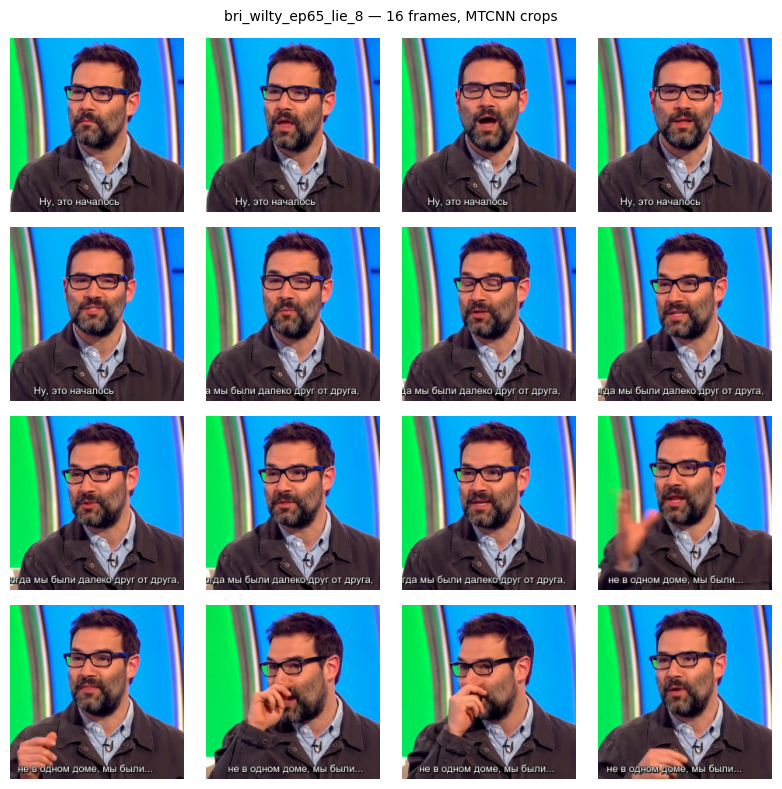

bri_wilty_ep65_lie_8: video (16, 384) float16 | audio (64, 768) float16
finite True True | std 2.420 0.161


In [39]:
import matplotlib.pyplot as plt

clip_id = ids[0]
crops = model_input(clip_id, "video", margin=1.75)["frames"]
figure, axes = plt.subplots(4, 4, figsize=(8, 8))
for axis, frame in zip(axes.ravel(), crops):
    axis.imshow(frame)
    axis.axis("off")
figure.suptitle(f"{clip_id} — {FRAMES} frames, MTCNN crops", fontsize=10)
plt.tight_layout()
plt.show()

video = np.load(cache_dir("dinov2-small-body", DATA) / f"{clip_id}.npy")
audio = np.load(cache_dir("wavlm-base-plus", DATA) / f"{clip_id}.npy")
print(f"{clip_id}: video {video.shape} {video.dtype} | audio {audio.shape} {audio.dtype}")
print(f"finite {np.isfinite(video).all()} {np.isfinite(audio).all()} | "
      f"std {video.std():.3f} {audio.std():.3f}")

## 8 — Full run

Both encoders over the whole protocol. A disconnect is not a disaster: run the cell again and
it continues from the last written file. Expect roughly 40–60 minutes on a T4; writing 1,671
small files to Drive is what makes it that long, not the forward passes.

In [40]:
for name, spec in ENCODERS.items():
    if name not in encoders:
        encoders[name] = build_encoder(spec)

for name, encoder in encoders.items():
    run_encoder(name, encoder, ids, force=FORCE)

text-minilm: 1296 to encode, 3 already cached


text-minilm:  10%|▉         | 128/1296 [00:28<05:08,  3.79clip/s]

  text-minilm: 129/1296 clips


text-minilm:  20%|█▉        | 257/1296 [02:26<17:40,  1.02s/clip]

  text-minilm: 258/1296 clips


text-minilm:  30%|██▉       | 386/1296 [04:44<15:34,  1.03s/clip]

... (13 outputs left out)

text-minilm:  99%|█████████▉| 1289/1296 [20:53<00:07,  1.03s/clip]

  text-minilm: 1290/1296 clips


text-minilm: 100%|██████████| 1296/1296 [21:00<00:00,  1.03clip/s]

  transcripts: 1299 in transcripts.json
text-minilm: 1299/1299 cached, 0 failed, 21.0 min


## 9 — Look at the transcripts

Ten clips at random, with their label. This is the guard the text stream needs: if the host's
question, the other players or the reveal of the round are in the transcript, a model can read the
answer from the words, and the stream would measure the game show rather than the lie. Read them
before building anything on top of this cache.

In [41]:
import json
import random

transcripts = json.loads((cache_dir("text-minilm", DATA) / "transcripts.json").read_text())
print(f"{len(transcripts)} transcripts")

words = sorted(len(text.split()) for text in transcripts.values())
print(f"words per clip: median {words[len(words) // 2]}, max {words[-1]}")

for clip_id in random.Random(0).sample(sorted(transcripts), min(10, len(transcripts))):
    clip = clips[clip_id]
    print(f"\n--- {clip_id}  |  {clip.label}  |  {clip.subject}")
    print(transcripts[clip_id] or "(empty)")

1299 transcripts
words per clip: median 14, max 80

--- sb_wilty_ep29_truth7  |  truth  |  David Mitchell
Basically, it's not really, you can't just screw it back on because the holes that the screws...

--- sb_wilty_ep35_truth10  |  truth  |  Mark Watson
It was quite a built up tournament, you see, it was a sort of best of seven. My dad called at the Watson Cup. I grew up in quite a competitive...

--- an_wilty_ep26_truth7  |  truth  |  Jack Dee
That's brilliant, Ray Charles, because I will remember, I remember from the sun, I'm therefore I will get Charles. And then very next year when we go I can confidently say hello.

--- ls_wilty_ep2_lie3  |  deception  |  Lee Mack
I actually employ Mark solely to manage my iPod.

--- yw_wilty_ep45_truth2  |  truth  |  Bill
The ocean okay which ocean was it it? It was the Indian

--- yw_wilty_ep43_truth7  |  truth  |  David O'Doherty
we would ring up one of these people, and as I had the most mature voice of the agency.

--- sb_wilty_ep33_truth1 

## 10 — Verify

Three checks before handing the cache to the training notebook: every split clip has a file,
the shapes are the ones the model will expect, and the arrays carry signal — a mean-pooled
logistic regression on one fold is enough to tell a working cache from a broken one.

The probe is a **plumbing check, not a result**: the result comes from the five folds in
`train_tia.ipynb`.

Note the `cached_ids` intersection: the split sizes printed in section 2 are the protocol, the
sizes printed here are what the model will actually see.

In [42]:
for name in ENCODERS:
    directory = cache_dir(name, DATA)
    files = sorted(directory.glob("*.npy"))
    missing = [clip_id for clip_id in ids if not (directory / f"{clip_id}.npy").exists()]
    size_mb = sum(path.stat().st_size for path in files) / 1e6
    sample = np.load(files[0]) if files else np.zeros((0,))
    print(f"{name:16} {len(files):5d} files  {size_mb:7.1f} MB  "
          f"shape {sample.shape}  dtype {sample.dtype}  missing {len(missing)}")
    if missing:
        print("   first missing:", missing[:3], "-> run the cell in section 8 again")

text-minilm       1299 files      1.2 MB  shape (384,)  dtype float16  missing 0


In [43]:
from lib.dataset import CachedFeatures, make_loader


def cached_ids(clip_ids, cache):
    """Split clips that have an array in this cache.

    The splits are frozen on dataset.csv, the cache covers only the clips whose media
    and audio are on disk. Intersect here: a clip without a wav cannot be fed to the
    fusion model, and CachedFeatures rightly refuses a split with holes in it.
    """
    have = {path.stem for path in Path(cache).glob("*.npy")}
    return [clip_id for clip_id in clip_ids if clip_id in have]


train_ids, val_ids, holdout_ids = folds.subject(1)
usable = cached_ids(train_ids, cache_dir("dinov2-small", DATA))
usable = cached_ids(usable, cache_dir("wavlm-base-plus", DATA))
print(f"fold 1 train: {len(train_ids)} split clips -> {len(usable)} with both encodings")
for name in ENCODERS:
    dataset = CachedFeatures(usable, clips, cache_dir(name, DATA))
    item, _ = dataset[0]
    batch_x, batch_y = next(iter(make_loader(dataset, batch_size=8)))
    print(f"{name:16} {len(dataset):4d} clips  item {tuple(item.shape)}  "
          f"batch {tuple(batch_x.shape)}  labels {tuple(batch_y.shape)}")

fold 1 train: 1011 split clips -> 904 with both encodings
text-minilm       904 clips  item (384,)  batch (8, 384)  labels (8,)


In [44]:
# Sanity check, not a result: is there any signal in the cache at all?
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def pooled_features(name, clip_ids):
    """Mean over time for a (tokens, dim) array; a flat vector (the text cache) as it is."""
    directory = cache_dir(name, DATA)
    rows = []
    for clip_id in clip_ids:
        array = np.load(directory / f"{clip_id}.npy").astype(np.float32)
        rows.append(array if array.ndim == 1 else array.mean(axis=0))
    return np.stack(rows)


def in_every_cache(clip_ids):
    """The probe concatenates all encoders, so a clip must have an array in every one."""
    return [clip_id for clip_id in clip_ids
            if all((cache_dir(name, DATA) / f"{clip_id}.npy").exists() for name in ENCODERS)]


train_ids, val_ids, _ = folds.subject(1)
train_ids, val_ids = in_every_cache(train_ids), in_every_cache(val_ids)
n = min(len(train_ids), len(val_ids), 400)
x_train = np.hstack([pooled_features(name, train_ids[:n]) for name in ENCODERS])
x_val = np.hstack([pooled_features(name, val_ids[:n]) for name in ENCODERS])
y_train, y_val = clips.labels(train_ids[:n]), clips.labels(val_ids[:n])

if len(np.unique(y_train)) < 2 or len(np.unique(y_val)) < 2:
    print("probe skipped: a slice has a single class")
else:
    probe = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=2000, class_weight="balanced"))
    probe.fit(x_train, y_train)
    auc = roc_auc_score(y_val, probe.predict_proba(x_val)[:, 1])
    print(f"fold-1 validation AUC {auc:.3f}  (n={n}, majority "
          f"{max(y_val.mean(), 1 - y_val.mean()):.3f})")

ValueError: Expected 2D array, got 1D array instead:
array=[-5.1558000e-04 -4.3053212e-04  4.2374604e-04 -8.7554414e-05
 -1.5552683e-03 -1.4869781e-03 -5.0467206e-04 -1.6731179e-04
  8.7613799e-04  8.7846006e-04  3.8107857e-05 -3.2417072e-04
  6.9379312e-04 -2.0467180e-04  5.7247281e-04  2.4212834e-04
 -8.1797829e-04 -4.1082036e-05  7.7674986e-04 -4.9606338e-04
 -2.3989519e-04 -8.0641854e-04 -1.0406164e-04 -3.7101409e-04
 -6.7543052e-04  1.6930979e-04 -1.6867971e-03  8.1403973e-04
  5.3509325e-04  1.2521849e-04  1.4480753e-03 -1.3631738e-04
 -1.0817992e-03  1.5625722e-03  9.4953179e-04  1.1858436e-03
  1.4471273e-03 -4.3145008e-04  1.0358045e-03  6.7358697e-04
  3.6574280e-04  3.6075106e-04  1.1166310e-03  1.1932036e-03
 -3.5785898e-04  1.0779882e-03 -5.7262898e-04  9.1579539e-04
 -5.2895147e-04 -2.0378658e-04 -3.3494085e-05 -6.6602387e-04
  1.5519249e-04  1.5380121e-03 -1.7780671e-04  9.7609744e-05
  6.9363788e-04 -1.2094922e-03 -4.0620039e-04  7.1395916e-04
 -8.6457981e-04  1.2560301

## 11 — Next

The two folders are now what `train_tia.ipynb` reads:

```python
from lib.dataset import CachedFeatures, cache_dir

# The split is the protocol; the cache is what exists on disk. Always intersect: clips
# without audio stay in the split but have no array here.
train_ids = cached_ids(folds.subject(1)[0], cache_dir("dinov2-small", DATA))
train_ids = cached_ids(train_ids, cache_dir("wavlm-base-plus", DATA))

video = CachedFeatures(train_ids, clips, cache_dir("dinov2-small", DATA))
audio = CachedFeatures(train_ids, clips, cache_dir("wavlm-base-plus", DATA))
```

Post in the group chat: the two encoder names, the number of clips, the cache size and the
`dataset.csv` fingerprint printed in section 2 — two members with different fingerprints are
not training on the same data.

To add SigLIP later, add one entry to `ENCODERS` and run sections 7–8 again: the existing
folders are untouched, and `train_tia.ipynb` can compare the two visual backbones on the same
clips without re-decoding anything.